# Home Credit Default Risk: initial EDA and baseline

This educational project uses only `application_train.csv` from the official [Home Credit Default Risk competition](https://www.kaggle.com/competitions/home-credit-default-risk). Kaggle may require an account and acceptance of its rules to access the file. No auxiliary tables are included. The verified schema (307,511 rows, 122 columns, `SK_ID_CURR`, and `TARGET`) matches the official training file.

**Objective:** predict `TARGET` (repayment difficulty) as a classification exercise. This baseline is not suitable for real credit decisions.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, confusion_matrix, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
DATA_PATH = Path("data/raw/application_train.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Could not find {DATA_PATH}. Run the notebook from the project root.")

## 1. Load and verify the data file

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Identifier/target columns:", [c for c in ["SK_ID_CURR", "TARGET"] if c in df])
assert df.shape == (307_511, 122), "The file dimensions do not match the expected official training data."
assert {0, 1} == set(df["TARGET"].dropna().unique()), "TARGET must be binary (0/1)."


Dimensions: 307,511 rows x 122 columns
Identifier/target columns: ['SK_ID_CURR', 'TARGET']


## 2. Data types, missing values, and duplicates


Data types:


,column_count
data_type,
float64,65
int64,41
str,16


,missing_percentage
COMMONAREA_AVG,69.87
COMMONAREA_MODE,69.87
COMMONAREA_MEDI,69.87
NONLIVINGAPARTMENTS_MEDI,69.43
NONLIVINGAPARTMENTS_MODE,69.43
NONLIVINGAPARTMENTS_AVG,69.43
FONDKAPREMONT_MODE,68.39
LIVINGAPARTMENTS_AVG,68.35
LIVINGAPARTMENTS_MEDI,68.35
LIVINGAPARTMENTS_MODE,68.35


Exact duplicate rows: 0
Duplicate applicant IDs: 0


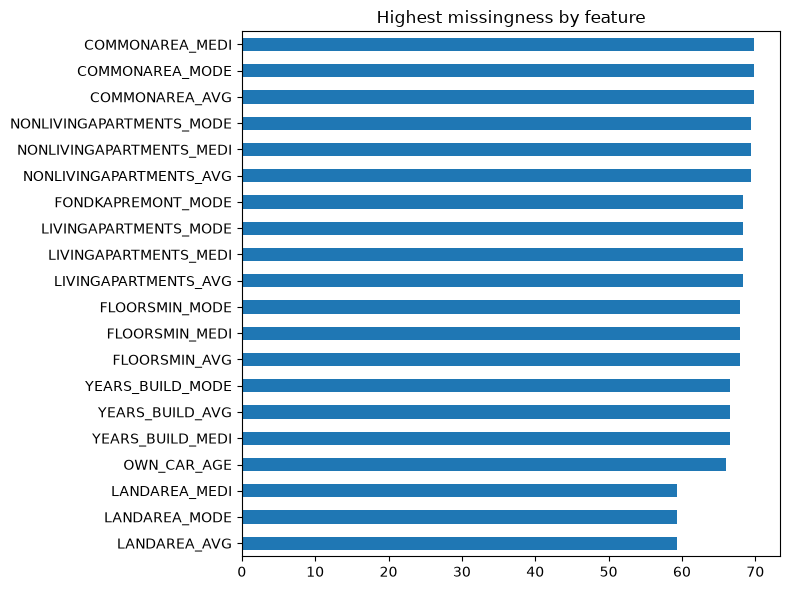

In [3]:
print("\nData types:")
display(df.dtypes.value_counts().rename_axis("data_type").to_frame("column_count"))
missing = (df.isna().mean().mul(100).sort_values(ascending=False)
           .rename("missing_percentage").to_frame())
display(missing.head(20).round(2))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate applicant IDs:", int(df["SK_ID_CURR"].duplicated().sum()))
missing.head(20).sort_values("missing_percentage").plot.barh(legend=False, figsize=(8, 6), title="Highest missingness by feature")
plt.tight_layout()
plt.show()

## 3. Distributions and target variable

,count,proportion
TARGET,,
0,282686,0.919271
1,24825,0.080729


Positive-class proportion (TARGET=1): 8.0729%


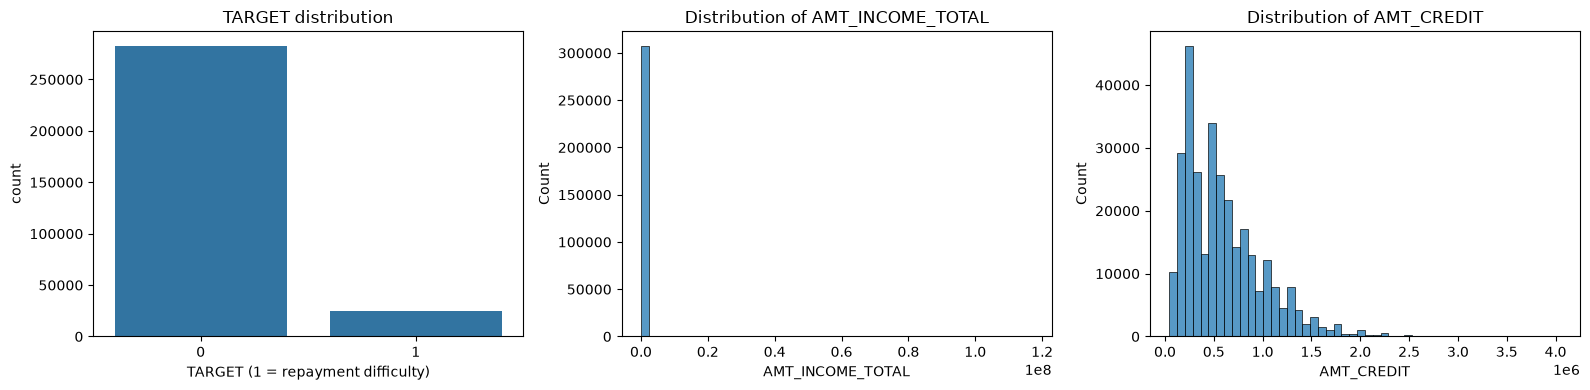

In [4]:
target_counts = df["TARGET"].value_counts().sort_index()
target_share = df["TARGET"].value_counts(normalize=True).sort_index()
display(pd.DataFrame({"count": target_counts, "proportion": target_share}))
print(f"Positive-class proportion (TARGET=1): {target_share.loc[1]:.4%}")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="TARGET", ax=axes[0])
axes[0].set_title("TARGET distribution")
axes[0].set_xlabel("TARGET (1 = repayment difficulty)")
for col, ax in zip(["AMT_INCOME_TOTAL", "AMT_CREDIT"], axes[1:]):
    sns.histplot(data=df, x=col, bins=50, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

## 4. Leakage checks and feature selection

`SK_ID_CURR` is an identifier and is excluded from the features. `TARGET` is kept separate as the label. The training file contains attributes reported when the loan was requested and does not include auxiliary tables with later behavior, so there is no column that is clearly derived from the outcome. Any feature with semantics that could occur after the decision should be reviewed before expanding the project. Column names and data types are inspected below.

The EDA statistics describe the full source file. For modeling, preprocessing is fitted only on the training subset.

In [5]:
print("Columns (for semantic review):")
print(df.columns.tolist())
X = df.drop(columns=["SK_ID_CURR", "TARGET"])
y = df["TARGET"].astype("int8")
print(f"Predictive features: {X.shape[1]}; TARGET is kept separate: {y.name}")

Columns (for semantic review):
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUI

## 5. Stratified 60/20/20 split

In [6]:
# First reserve 40%; then split that portion equally into validation and test.
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp
)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "percentage": [len(y_train)/len(y), len(y_val)/len(y), len(y_test)/len(y)],
    "proportion_TARGET_1": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"])
display(split_summary)

,rows,percentage,proportion_TARGET_1
train,184506,0.599998,0.080729
validation,61502,0.199999,0.080729
test,61503,0.200003,0.080728


## 6. Pipeline and logistic regression baseline

In [7]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=200, solver="liblinear", random_state=42)),
])
print(f"Numeric features: {len(numeric_features)}; categorical features: {len(categorical_features)}")
model.fit(X_train, y_train)

Numeric features: 104; categorical features: 16


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcol

## 7. Validation evaluation

In [8]:
val_probability = model.predict_proba(X_val)[:, 1]
val_prediction = (val_probability >= 0.5).astype("int8")
metrics = {
    "ROC-AUC": roc_auc_score(y_val, val_probability),
    "Average Precision": average_precision_score(y_val, val_probability),
    "Precision (threshold 0.5)": precision_score(y_val, val_prediction, zero_division=0),
    "Recall (threshold 0.5)": recall_score(y_val, val_prediction, zero_division=0),
}
print("Positive-class rate in validation:", f"{y_val.mean():.4%}")
display(pd.Series(metrics, name="validation"))
cm = confusion_matrix(y_val, val_prediction, labels=[0, 1])
display(pd.DataFrame(cm, index=["actual_0", "actual_1"], columns=["predicted_0", "predicted_1"]))

Positive-class rate in validation: 8.0729%


ROC-AUC                      0.746837
Average Precision            0.227117
Precision (threshold 0.5)    0.534483
Recall (threshold 0.5)       0.012487
Name: validation, dtype: float64

,predicted_0,predicted_1
actual_0,56483,54
actual_1,4903,62


## Initial conclusions

The positive class is a minority class, so Average Precision and Recall complement ROC-AUC and precision. A 0.5 threshold is used only as an initial reference. The test set is reserved for a later final evaluation and is not used for model selection or tuning. This result is educational and must not be used for real credit decisions.

# Phase 2: model comparison, small-scale tuning, and selection

The exact `X_train`, `X_val`, `X_test` objects and their labels created above are retained. **`X_test` is not used for fitting or evaluation in this phase.** Each candidate fits its own preprocessor using only the training set. Average Precision is the primary metric because of class imbalance; ROC-AUC is complementary.

In [9]:
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, f1_score,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, confusion_matrix)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import time
import psutil

# Add the Phase 1 baseline without changing its configuration.
candidates = {
    "Logistic Regression (baseline)": (model, {
        "C": 1.0, "solver": "liblinear", "max_iter": 200, "class_weight": None
    }, model.predict_proba(X_val)[:, 1]),
}
fit_rows = []
process = psutil.Process()
peak_rss_mb = process.memory_info().rss / 1024**2

def record_candidate(name, estimator, params):
    global peak_rss_mb
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("classifier", estimator)])
    rss_before = process.memory_info().rss / 1024**2
    started = time.perf_counter()
    pipe.fit(X_train, y_train)
    elapsed = time.perf_counter() - started
    probability = pipe.predict_proba(X_val)[:, 1]
    rss_after = process.memory_info().rss / 1024**2
    peak_rss_mb = max(peak_rss_mb, rss_after)
    candidates[name] = (pipe, params, probability)
    fit_rows.append({"model": name, "ROC-AUC": roc_auc_score(y_val, probability),
                     "Average Precision": average_precision_score(y_val, probability),
                     "fit_seconds": elapsed, "rss_after_fit_mib": rss_after,
                     "rss_delta_fit_mib": rss_after-rss_before})

# Keep the random forest configurations small to limit memory and runtime.
rf_settings = [
    {"n_estimators": 100, "max_depth": 12, "min_samples_leaf": 50, "max_features": "sqrt"},
    {"n_estimators": 160, "max_depth": 16, "min_samples_leaf": 100, "max_features": "sqrt"},
]
for i, params in enumerate(rf_settings, start=1):
    record_candidate(f"Random Forest {i}",
        RandomForestClassifier(**params, n_jobs=2, random_state=42, class_weight=None), params)

xgb_settings = [
    {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.08, "min_child_weight": 10},
    {"n_estimators": 180, "max_depth": 4, "learning_rate": 0.06, "min_child_weight": 10},
]
for i, params in enumerate(xgb_settings, start=1):
    record_candidate(f"XGBoost {i}",
        XGBClassifier(**params, subsample=0.8, colsample_bytree=0.8,
                      reg_lambda=5, max_bin=128, tree_method="hist",
                      n_jobs=2, random_state=42, eval_metric="logloss",
                      objective="binary:logistic"), params)

comparison = pd.DataFrame(fit_rows).set_index("model")
baseline_scores = candidates["Logistic Regression (baseline)"][2]
baseline_row = pd.DataFrame([{"ROC-AUC": roc_auc_score(y_val, baseline_scores),
    "Average Precision": average_precision_score(y_val, baseline_scores),
    "fit_seconds": np.nan, "rss_after_fit_mib": np.nan, "rss_delta_fit_mib": np.nan}],
    index=["Logistic Regression (baseline)"])
comparison = pd.concat([baseline_row, comparison])
comparison["parameters"] = [str(candidates[name][1]) for name in comparison.index]
display(comparison.sort_values("Average Precision", ascending=False).round(4))
print(f"Current RSS after fitting (MiB): {process.memory_info().rss/1024**2:.1f}; maximum observed while sampling after fits: {peak_rss_mb:.1f}")

,ROC-AUC,Average Precision,fit_seconds,rss_after_fit_mib,rss_delta_fit_mib,parameters
XGBoost 2,0.7554,0.2446,8.1708,1211.8906,6.6953,"{'n_estimators': 180, 'max_depth': 4, 'learnin..."
XGBoost 1,0.7495,0.2365,6.5169,1205.1953,75.1797,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
Logistic Regression (baseline),0.7468,0.2271,NaN,NaN,NaN,"{'C': 1.0, 'solver': 'liblinear', 'max_iter': ..."
Random Forest 1,0.7381,0.2239,16.5175,1118.4805,25.0703,"{'n_estimators': 100, 'max_depth': 12, 'min_sa..."
Random Forest 2,0.7394,0.2230,24.3974,1130.0156,11.5352,"{'n_estimators': 160, 'max_depth': 16, 'min_sa..."


Current RSS after fitting (MiB): 1211.9; maximum observed while sampling after fits: 1211.9


## Precision–Recall curve and decision thresholds

The candidate with the highest Average Precision on validation is selected. Candidate selection and threshold comparison use validation only, so these figures are selection estimates rather than an independent final result.

This rerun diagnostic threshold is not the frozen production threshold. Historical recorded metrics below retain their original provenance and may differ from newly executed comparisons.

The metric provenance review in `experiments/REPORT.md` documents agreement with the earlier no-engineering control and the unresolved provenance gap for the older reference.

Best candidate by Average Precision: XGBoost 2
Configuration parameters: {'n_estimators': 180, 'max_depth': 4, 'learning_rate': 0.06, 'min_child_weight': 10}


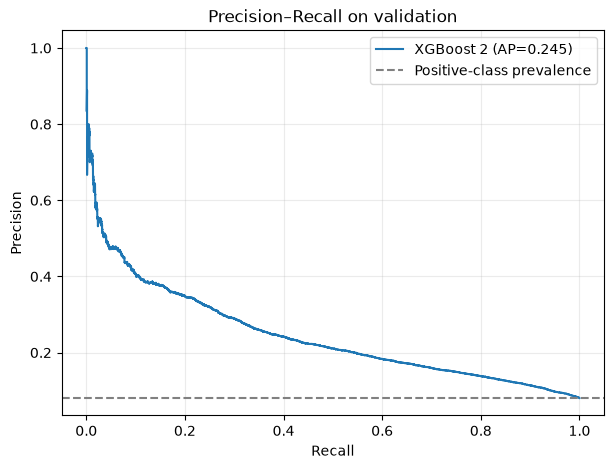

,precision,recall,F1,"confusion_matrix [[TN, FP], [FN, TP]]"
threshold,,,,
0.100000,0.1846,0.5944,0.2817,"[[43500, 13037], [2014, 2951]]"
0.151809,0.2418,0.4006,0.3016,"[[50301, 6236], [2976, 1989]]"
0.200000,0.2975,0.2788,0.2878,"[[53269, 3268], [3581, 1384]]"
0.300000,0.3903,0.1146,0.1772,"[[55648, 889], [4396, 569]]"
0.500000,0.7033,0.0129,0.0253,"[[56510, 27], [4901, 64]]"


Threshold that maximizes F1 on validation: 0.151809 (not an independent estimate).


In [10]:
ranked = comparison.sort_values("Average Precision", ascending=False)
best_name = ranked.index[0]
best_model, best_params, best_probability = candidates[best_name]
print("Best candidate by Average Precision:", best_name)
print("Configuration parameters:", best_params)
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_val, best_probability)
plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve, label=f"{best_name} (AP={average_precision_score(y_val, best_probability):.3f})")
plt.axhline(y_val.mean(), linestyle="--", color="gray", label="Positive-class prevalence")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–Recall on validation")
plt.legend(); plt.grid(alpha=0.25); plt.show()

# Compare predefined thresholds and the threshold that maximizes F1 on validation.
f1_values = 2 * precision_curve[:-1] * recall_curve[:-1] / np.maximum(precision_curve[:-1] + recall_curve[:-1], 1e-12)
best_f1_threshold = float(pr_thresholds[np.argmax(f1_values)])
thresholds = [0.10, 0.20, 0.30, 0.50, best_f1_threshold]
threshold_rows = []
for threshold in sorted(set(round(t, 6) for t in thresholds)):
    pred = (best_probability >= threshold).astype("int8")
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "confusion_matrix [[TN, FP], [FN, TP]]": confusion_matrix(y_val, pred, labels=[0,1]).tolist(),
    })
threshold_table = pd.DataFrame(threshold_rows).set_index("threshold")
display(threshold_table.round(4))
print(f"Threshold that maximizes F1 on validation: {best_f1_threshold:.6f} (not an independent estimate).")

## Feature importance

The importance values available after encoding are shown for the selected candidate. For XGBoost and Random Forest, these values are based on gain or impurity reduction; they are diagnostic and not causal. For categorical variables, importance is reported separately for each encoded category.

In [11]:
classifier = best_model.named_steps["classifier"]
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
if hasattr(classifier, "feature_importances_"):
    importance = pd.Series(classifier.feature_importances_, index=feature_names)
    display(importance.sort_values(ascending=False).head(20).rename("importance").to_frame())
elif hasattr(classifier, "coef_"):
    importance = pd.Series(np.abs(classifier.coef_[0]), index=feature_names)
    display(importance.sort_values(ascending=False).head(20).rename("absolute_coefficient").to_frame())
else:
    print("This estimator does not expose feature importance directly.")

print("X_test and y_test were not accessed in Phase 2.")

,importance
numeric__EXT_SOURCE_2,0.054776
numeric__EXT_SOURCE_3,0.053378
numeric__missingindicator_AMT_REQ_CREDIT_BUREAU_DAY,0.036858
categorical__NAME_EDUCATION_TYPE_Higher education,0.031959
numeric__missingindicator_AMT_REQ_CREDIT_BUREAU_HOUR,0.025152
categorical__CODE_GENDER_F,0.022228
numeric__FLAG_DOCUMENT_3,0.021697
categorical__CODE_GENDER_M,0.021422
numeric__FLAG_EMP_PHONE,0.020295
categorical__NAME_INCOME_TYPE_Pensioner,0.017497


X_test and y_test were not accessed in Phase 2.


## Sensitivity check: model without `CODE_GENDER`

As a limited sensitivity check, XGBoost 2 is refitted with the same parameters and the same training/validation split, excluding `CODE_GENDER`. The validation metrics are compared without automatically changing the selected candidate. This predictive performance comparison is not a fairness evaluation.

In [12]:
from sklearn.compose import ColumnTransformer

X_train_no_gender = X_train.drop(columns=["CODE_GENDER"])
X_val_no_gender = X_val.drop(columns=["CODE_GENDER"])
numeric_no_gender = X_train_no_gender.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_no_gender = X_train_no_gender.select_dtypes(exclude=["number", "bool"]).columns.tolist()
preprocessor_no_gender = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_no_gender),
    ("categorical", categorical_pipeline, categorical_no_gender),
])
xgb_no_gender = Pipeline([
    ("preprocessor", preprocessor_no_gender),
    ("classifier", XGBClassifier(
        n_estimators=180, max_depth=4, learning_rate=0.06, min_child_weight=10,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, max_bin=128,
        tree_method="hist", n_jobs=2, random_state=42, eval_metric="logloss",
        objective="binary:logistic")),
])
xgb_no_gender.fit(X_train_no_gender, y_train)
no_gender_probability = xgb_no_gender.predict_proba(X_val_no_gender)[:, 1]
gender_sensitivity = pd.DataFrame([
    {"variant": "XGBoost 2 with CODE_GENDER",
     "ROC-AUC": roc_auc_score(y_val, candidates["XGBoost 2"][2]),
     "Average Precision": average_precision_score(y_val, candidates["XGBoost 2"][2])},
    {"variant": "XGBoost 2 without CODE_GENDER",
     "ROC-AUC": roc_auc_score(y_val, no_gender_probability),
     "Average Precision": average_precision_score(y_val, no_gender_probability)},
]).set_index("variant")
gender_sensitivity.loc["change without CODE_GENDER - baseline"] = (gender_sensitivity.iloc[1] - gender_sensitivity.iloc[0]).values
display(gender_sensitivity.round(6))

,ROC-AUC,Average Precision
variant,,
XGBoost 2 with CODE_GENDER,0.755400,0.244557
XGBoost 2 without CODE_GENDER,0.752788,0.241797
change without CODE_GENDER - baseline,-0.002611,-0.002760



## Phase 4B: recorded feature engineering experiments

The tables below load the aggregate validation and cross-validation results recorded in `experiments/validation_results.json`. They do not retrain candidates or evaluate the test set. See `experiments/REPORT.md` for the protocol, feature ablation, and limitations.

In [13]:
import json
from pathlib import Path

experiment_results = json.loads(Path("experiments/validation_results.json").read_text(encoding="utf-8"))
validation_rows = [{
    "Model": row["model"],
    "ROC-AUC": row["roc_auc"],
    "Average Precision": row["average_precision"],
    "Fit + validation prediction (seconds)": row["fit_and_validation_predict_seconds"],
} for row in experiment_results["validation_results"]]
validation_rows.append({
    "Model": "Reported XGBoost reference",
    "ROC-AUC": experiment_results["reference_validation"]["roc_auc"],
    "Average Precision": experiment_results["reference_validation"]["average_precision"],
    "Fit + validation prediction (seconds)": None,
})
display(pd.DataFrame(validation_rows).set_index("Model").sort_values("Average Precision", ascending=False).round(6))

cv_rows = [{
    "Model": row["model"],
    "ROC-AUC mean": row["mean_roc_auc"],
    "ROC-AUC std": row["std_roc_auc"],
    "Average Precision mean": row["mean_average_precision"],
    "Average Precision std": row["std_average_precision"],
} for row in experiment_results["cross_validation"]]
display(pd.DataFrame(cv_rows).set_index("Model").sort_values("Average Precision mean", ascending=False).round(6))

ablation_results = json.loads(Path("experiments/feature_ablation.json").read_text(encoding="utf-8"))
ablation_rows = [{
    "Model": row["model"],
    "ROC-AUC": row["roc_auc"],
    "Average Precision": row["average_precision"],
    "AP change vs. no engineered features": row["delta_average_precision_vs_no_engineered_features"],
} for row in ablation_results["results"]]
display(pd.DataFrame(ablation_rows).set_index("Model").round(6))

isolation_result = json.loads(Path("experiments/feature_isolation.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{
    "Model": isolation_result["model"],
    "ROC-AUC": isolation_result["roc_auc"],
    "Average Precision": isolation_result["average_precision"],
    "Fit + validation prediction (seconds)": isolation_result["seconds"],
}]).set_index("Model").round(6))

,ROC-AUC,Average Precision,Fit + validation prediction (seconds)
Model,,,
LightGBM tuned + features,0.767261,0.256644,26.251898
LightGBM initial + features,0.766480,0.254957,20.462765
XGBoost tuned + features,0.760463,0.248969,11.037739
XGBoost base + features,0.759695,0.247879,10.032320
XGBoost base + features without CODE_GENDER,0.758950,0.247849,9.854574
Reported XGBoost reference,0.755089,0.243390,NaN


,ROC-AUC mean,ROC-AUC std,Average Precision mean,Average Precision std
Model,,,,
LightGBM tuned + features,0.762720,0.001538,0.245235,0.005388
LightGBM initial + features,0.760665,0.001728,0.242435,0.005484
XGBoost tuned + features,0.757857,0.001854,0.240012,0.006688


,ROC-AUC,Average Precision,AP change vs. no engineered features
Model,,,
No engineered features,0.755400,0.244557,0.000000
All except DAYS_EMPLOYED_365243,0.760874,0.249286,0.004729
All except CREDIT_INCOME_RATIO,0.760464,0.248473,0.003916
All except ANNUITY_INCOME_RATIO,0.760223,0.249865,0.005308
All except CREDIT_ANNUITY_RATIO,0.754757,0.244489,-0.000068
All except EMPLOYED_TO_AGE_RATIO,0.760943,0.249764,0.005207
All except INCOME_PER_PERSON,0.760625,0.250325,0.005768
All except EXT_SOURCE_MEAN,0.761193,0.250288,0.005731
All except EXT_SOURCE_STD,0.760250,0.249288,0.004731


,ROC-AUC,Average Precision,Fit + validation prediction (seconds)
Model,,,
XGBoost base + CREDIT_ANNUITY_RATIO only,0.761262,0.250715,10.257361



## Preserved XGBoost baseline feature importance

This summary is read from the approved model artifact, which was refitted on training plus validation. It reports model importance values for description only; these are not causal effects.

In [14]:
import joblib
approved_bundle = joblib.load("models/xgb_home_credit.joblib")
approved_pipeline = approved_bundle["model"]
approved_feature_names = approved_pipeline.named_steps["preprocessor"].get_feature_names_out()
approved_importances = approved_pipeline.named_steps["classifier"].feature_importances_
display(pd.Series(approved_importances, index=approved_feature_names).sort_values(ascending=False).head(20).rename("model_importance").to_frame())

,model_importance
numeric__EXT_SOURCE_2,0.060972
numeric__EXT_SOURCE_3,0.055955
numeric__missingindicator_AMT_REQ_CREDIT_BUREAU_MON,0.035070
categorical__NAME_INCOME_TYPE_Pensioner,0.029537
categorical__NAME_EDUCATION_TYPE_Higher education,0.028362
categorical__CODE_GENDER_M,0.026865
numeric__FLAG_EMP_PHONE,0.024251
numeric__missingindicator_AMT_REQ_CREDIT_BUREAU_DAY,0.020913
categorical__NAME_INCOME_TYPE_Working,0.020754
numeric__missingindicator_AMT_REQ_CREDIT_BUREAU_HOUR,0.020648
